# Lab-9(ML)

## Name-Daksh Khandelwal
## Class-B-B3-45

Aim:-A shopping mall collects information about
its customers, including Age, Annual Income, and Spending Score. The mall
management wants to segment customers into different groups so that promotional
offers and loyalty programs can be targeted more effectively. Develop machine
learning models using K-Means Clustering and Hierarchical Clustering algorithms
to identify customer segments and compare the performance of both clustering
techniques.

In [ ]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans,AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering
import scipy.cluster.hierarchy as sch
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize']=(8,5)

df = pd.read_csv("Wholesale customers data - Wholesale customers data.csv")

--- FIRST 5 ROWS ---
   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185 

--- DATASET SHAPE ---
Rows: 440, Columns: 8

--- DATA TYPES & NON-NULL COUNTS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5

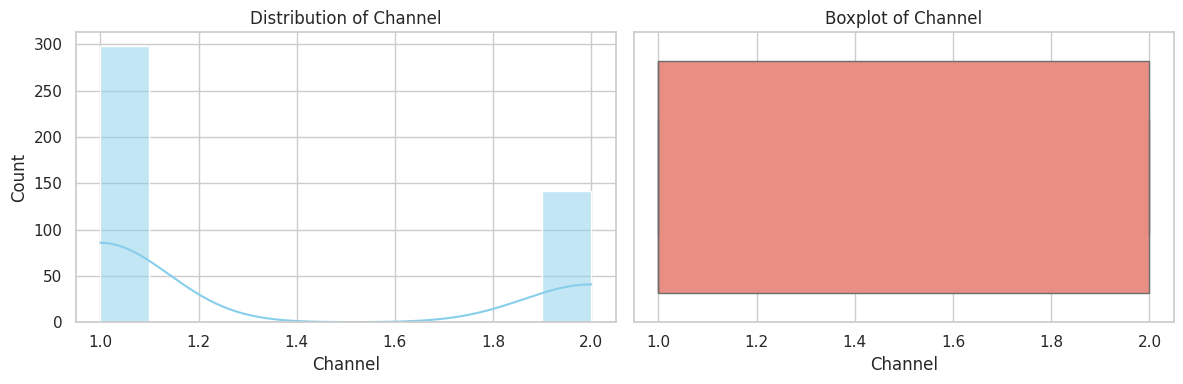

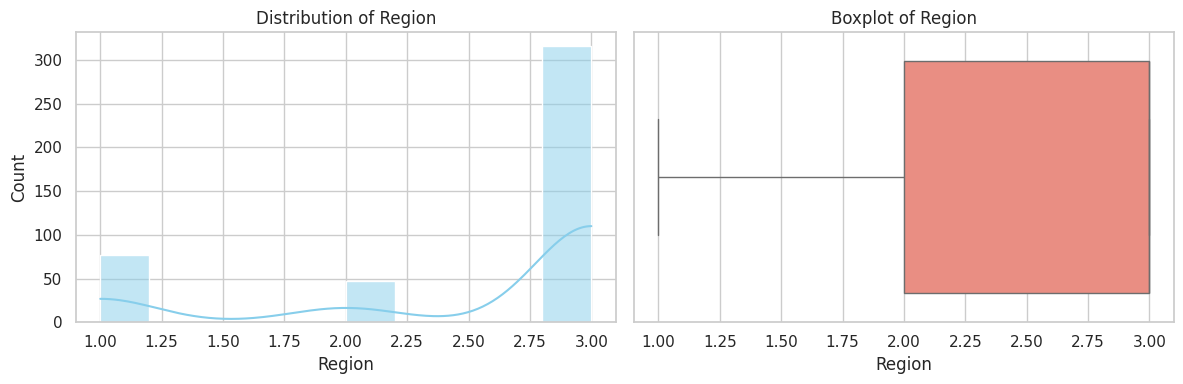

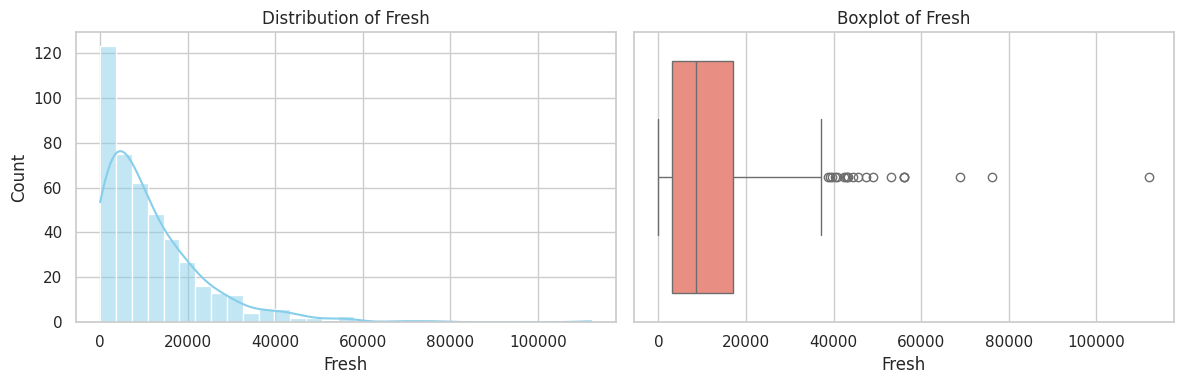

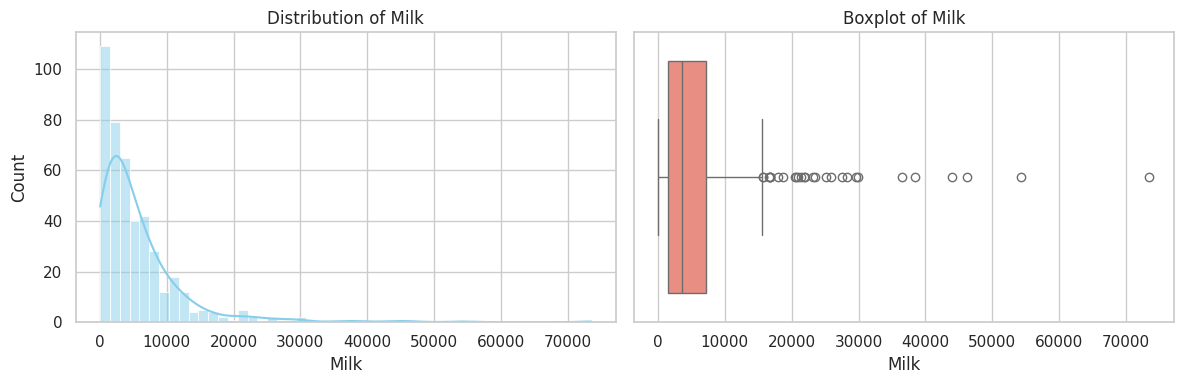

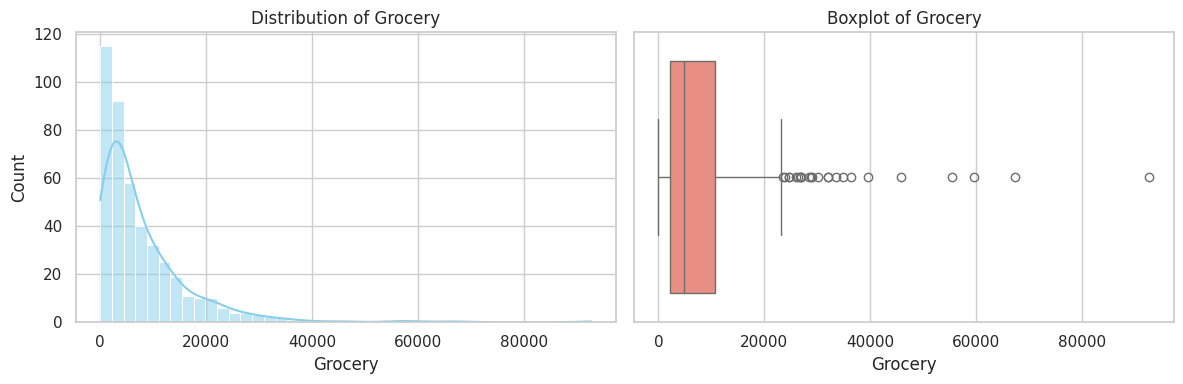

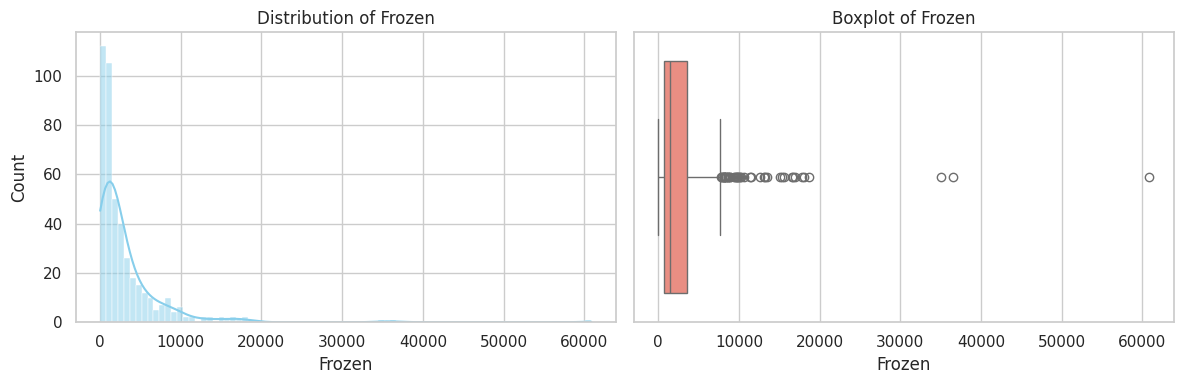

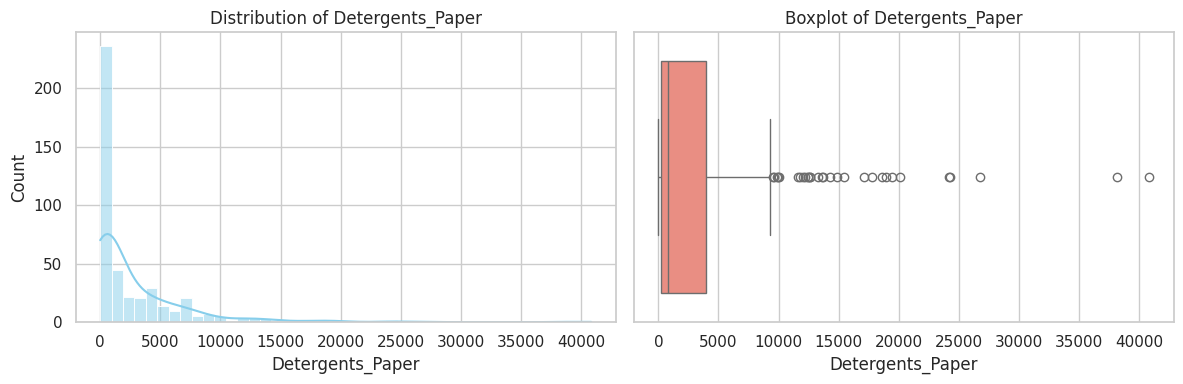

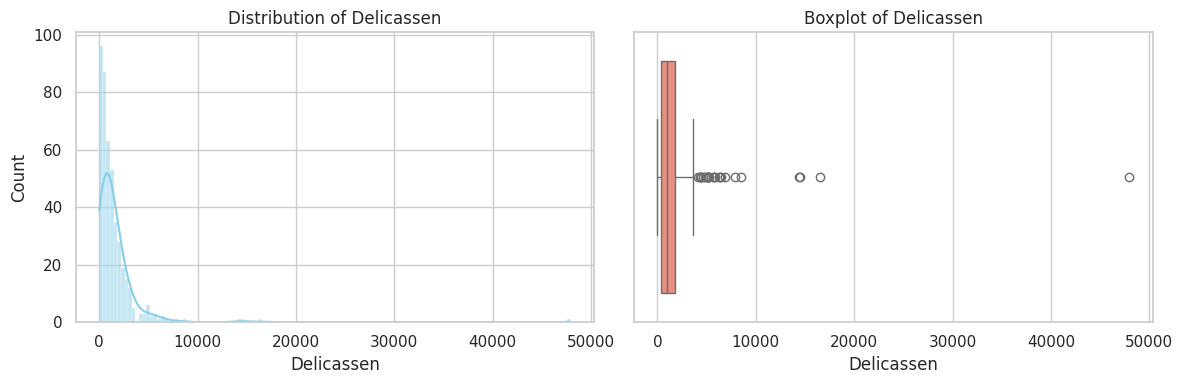

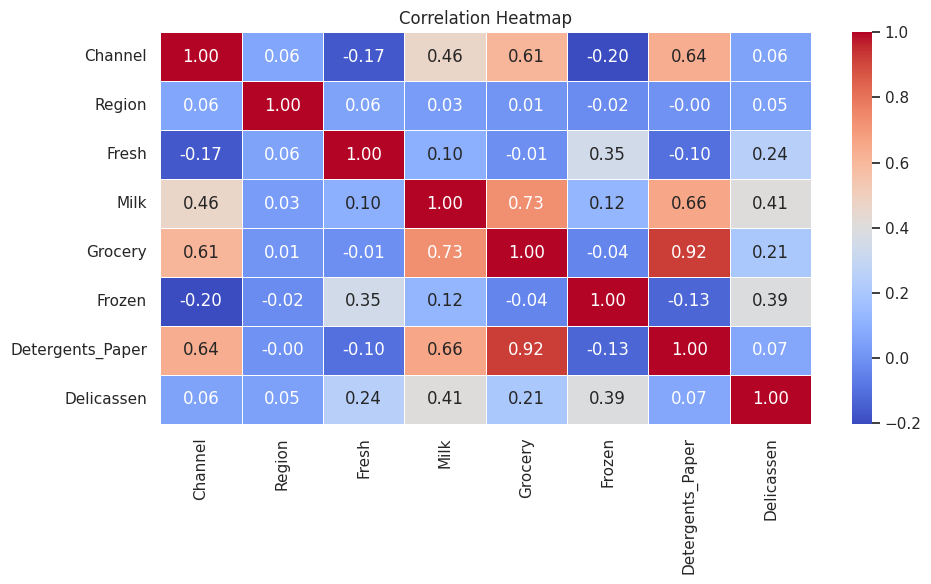

--- OUTLIER SUMMARY (IQR Method) ---
Channel: 0 outliers (0.0%)
Region: 0 outliers (0.0%)
Fresh: 20 outliers (4.55%)
Milk: 28 outliers (6.36%)
Grocery: 24 outliers (5.45%)
Frozen: 43 outliers (9.77%)
Detergents_Paper: 30 outliers (6.82%)
Delicassen: 27 outliers (6.14%)


In [ ]:
print("--- FIRST 5 ROWS ---")
print(df.head(), "\n")

print("--- DATASET SHAPE ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}\n")

print("--- DATA TYPES & NON-NULL COUNTS ---")
print(df.info(), "\n")

print("--- SUMMARY STATISTICS ---")
print(df.describe().T, "\n")

# 3. MISSING VALUES & DUPLICATES
print("--- DUPLICATE ROWS ---")
print(f"Total duplicates: {df.duplicated().sum()}\n")

print("--- MISSING VALUES ---")
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values found.\n")

# 4. UNIVARIATE ANALYSIS (Distributions & Boxplots)
num_cols = df.select_dtypes(include=[np.number]).columns

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Histogram / KDE
    sns.histplot(df[col], kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title(f'Distribution of {col}')

    # Boxplot for Outliers
    sns.boxplot(x=df[col], ax=axes[1], color='salmon')
    axes[1].set_title(f'Boxplot of {col}')

    plt.tight_layout()
    plt.show()

# 5. BIVARIATE ANALYSIS (Correlation Matrix)
if len(num_cols) > 1:
    plt.figure(figsize=(10, 6))
    corr = df[num_cols].corr()
    sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()

# 6. OUTLIER DETECTION (IQR Method)
print("--- OUTLIER SUMMARY (IQR Method) ---")
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f"{col}: {len(outliers)} outliers ({round(len(outliers)/len(df)*100, 2)}%)")

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

In [ ]:
# Create DataFrame with scaled features using df's existing columns and index
X_scaled_df = pd.DataFrame(X_scaled, columns=df.columns, index=df.index)

# Display the first few rows
X_scaled_df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,1.448652,0.590668,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,1.448652,0.590668,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,1.448652,0.590668,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,-0.690297,0.590668,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,1.448652,0.590668,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


In [ ]:
print(X_scaled_df.mean().round(3))

Channel             0.0
Region              0.0
Fresh              -0.0
Milk                0.0
Grocery            -0.0
Frozen              0.0
Detergents_Paper    0.0
Delicassen         -0.0
dtype: float64


In [ ]:
print("\nScaled feature standard deviations (approximately one):")
print(X_scaled_df.std().round(3))


Scaled feature standard deviations (approximately one):
Channel             1.001
Region              1.001
Fresh               1.001
Milk                1.001
Grocery             1.001
Frozen              1.001
Detergents_Paper    1.001
Delicassen          1.001
dtype: float64


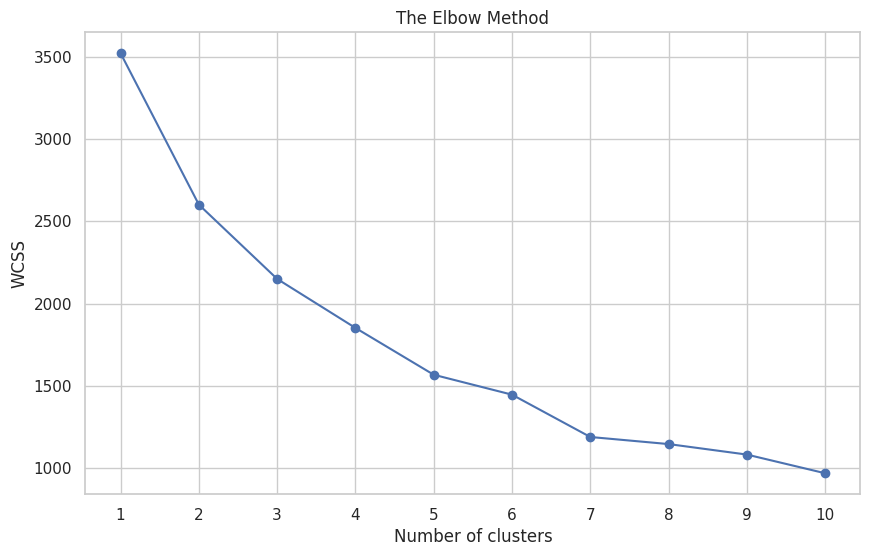

In [ ]:
wcss = []
k_values = range(1, 11)


for k in k_values:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)


plt.figure(figsize=(10, 6))
plt.plot(k_values, wcss, marker='o')
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [ ]:
silhouette_value = []

# Use range(2, 11) instead of (2, 11)
for k in range(2, 11):
    model = KMeans(n_clusters=k, init='k-means++', random_state=42)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_value.append(score)

# Create and display the table after the loop finishes
silhouette_table = pd.DataFrame({
    'Number of Clusters': list(range(2, 11)),
    'Silhouette Score': silhouette_value
})

print(silhouette_table.round(4))

   Number of Clusters  Silhouette Score
0                   2            0.3742
1                   3            0.3568
2                   4            0.3482
3                   5            0.3570
4                   6            0.3559
5                   7            0.3553
6                   8            0.3563
7                   9            0.3589
8                  10            0.3681


In [ ]:
suggested_k = int(
    silhouette_table[silhouette_table['Silhouette Score'] == silhouette_table['Silhouette Score'].max()]['Number of Clusters']
)
print(f"Suggested number of clusters: {suggested_k}")

Suggested number of clusters: 2


In [ ]:
K = suggested_k
kmeans_model = KMeans(n_clusters=K, init='k-means++', random_state=42)
kmeans_labels = kmeans_model.fit_predict(X_scaled)


In [ ]:
df_kmeans = df.copy()
df_kmeans["Kmeans_cluster"] = kmeans_labels
print(df_kmeans["Kmeans_cluster"].value_counts().sort_index())
print(df_kmeans.head())


Kmeans_cluster
0    140
1    300
Name: count, dtype: int64
   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  \
0        2       3  12669  9656     7561     214              2674   
1        2       3   7057  9810     9568    1762              3293   
2        2       3   6353  8808     7684    2405              3516   
3        1       3  13265  1196     4221    6404               507   
4        2       3  22615  5410     7198    3915              1777   

   Delicassen  Kmeans_cluster  
0        1338               0  
1        1776               0  
2        7844               0  
3        1788               1  
4        5185               0  


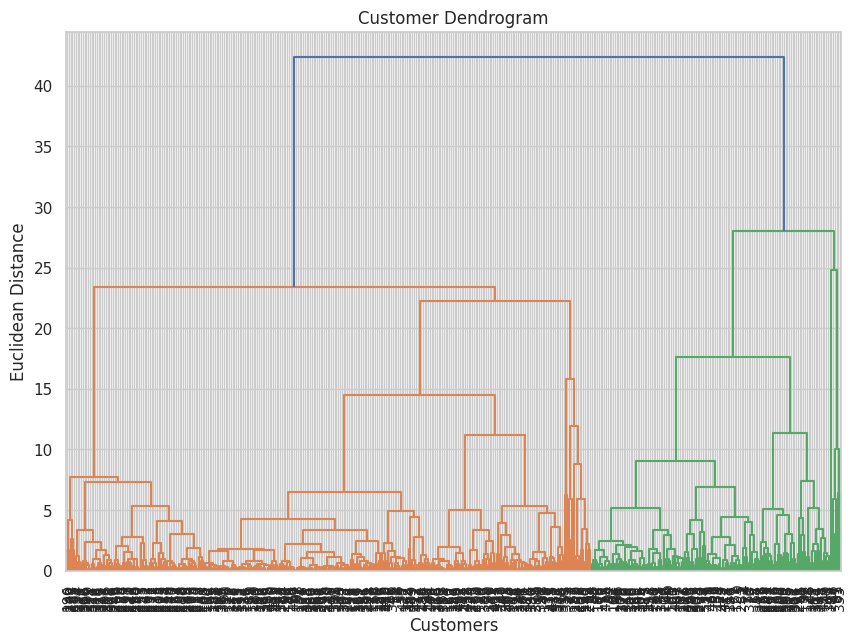

In [ ]:
Z = linkage(X_scaled, method='ward')
plt.figure(figsize=(10, 7))
plt.title("Customer Dendrogram")
dend = dendrogram(Z,leaf_rotation=90, leaf_font_size=10)
plt.xlabel("Customers")
plt.ylabel("Euclidean Distance")
plt.show()

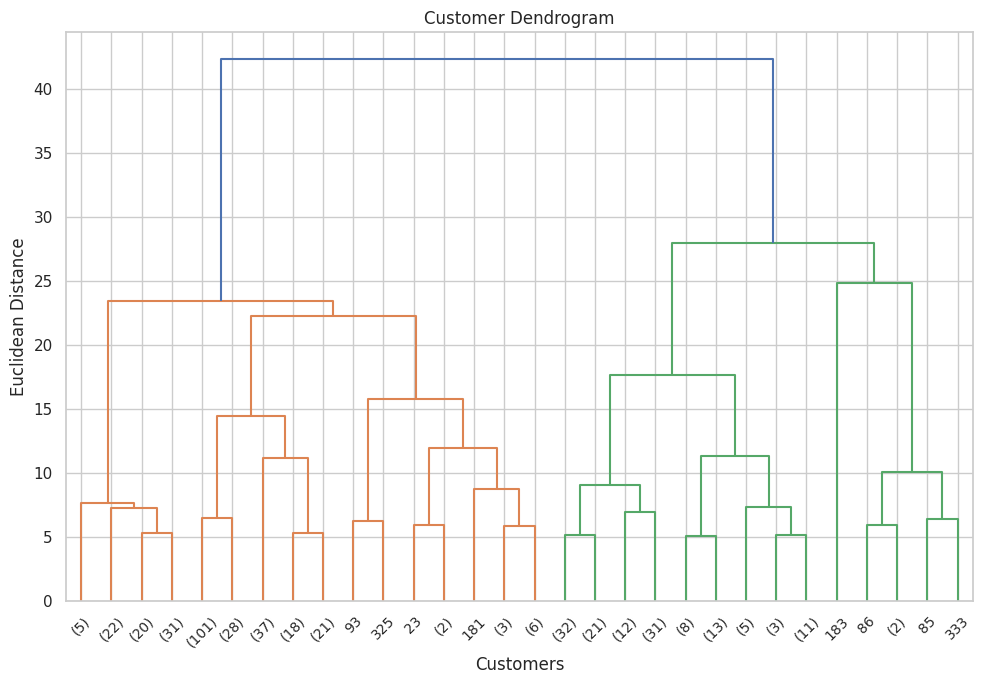

In [ ]:
plt.figure(figsize=(10, 7))
plt.title("Customer Dendrogram")
dend = dendrogram(Z, truncate_mode="lastp",p=30,show_leaf_counts=True,leaf_rotation=45)
plt.xlabel("Customers")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()

Explained Variance Ratio (first two components): 0.611


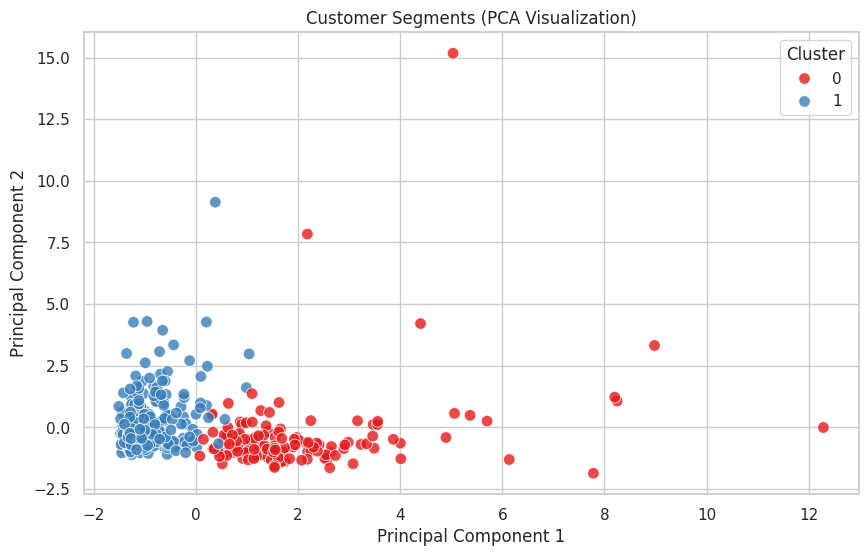

In [ ]:
# Apply PCA to reduce dimensionality to 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Explained Variance Ratio (first two components):", round(pca.explained_variance_ratio_[:2].sum(), 3))

# Create DataFrame for plotting
plot_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
plot_df["Kmeans_cluster"] = kmeans_labels

# Scatter plot of PCA components colored by K-Means clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x="PC1",
    y="PC2",
    hue="Kmeans_cluster",
    data=plot_df,
    palette="Set1",  # Capitalized 'Set1' fixes the error
    s=70,
    alpha=0.8
)
plt.title("Customer Segments (PCA Visualization)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(True)
plt.show()

In [ ]:
def evaluate_clustering(X_data,labels,model_name):
  return{
      "Algorithim":model_name,
      "Silhouette Score":silhouette_score(X_data,labels),
      "Number of clusters":len(np.unique(labels))
  }

In [ ]:
# Ensure hierarchical labels are defined before creating the comparison DataFrame
hc = AgglomerativeClustering(n_clusters=suggested_k)
hierarchical_labels = hc.fit_predict(X_scaled)

# Evaluate and compare models
comparison = pd.DataFrame([
    evaluate_clustering(X_scaled, kmeans_labels, "KMeans"),
    evaluate_clustering(X_scaled, hierarchical_labels, "Hierarchical Clustering")
])

print(comparison)

                Algorithim  Silhouette Score  Number of clusters
0                   KMeans          0.374157                   2
1  Hierarchical Clustering          0.368021                   2


In [ ]:
cluster_sizes = pd.DataFrame({
    "K-means": pd.Series(kmeans_labels).value_counts().sort_index(),
    "Hierarchical": pd.Series(hierarchical_labels).value_counts().sort_index()
}).fillna(0).astype(int)

print("Cluster Sizes:")
print(cluster_sizes)

Cluster Sizes:
   K-means  Hierarchical
0      140           142
1      300           298


In [ ]:

features = df.columns
kmeans_profile = df[features].copy()
kmeans_profile["Cluster"] = kmeans_labels

kmeans_means = kmeans_profile.groupby("Cluster").mean()
kmeans_means.round(2)

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,,,
0,1.98,2.64,9575.61,11447.61,16774.73,1880.78,7389.94,2149.19
1,1.02,2.50,13131.82,3158.97,3833.67,3627.80,777.55,1233.52
